# Laboratorio 3: La tarea de clasificación - Ruta Alpes

**Caso:** Ruta Alpes, aplicación de asistencia de conducción con recomendación de cupones.

**Integrantes:** Juan Camilo Panadero - Jose Luis Parra

**Objetivo:** Construir y comparar modelos de clasificación (regresión logística, árbol de decisión y Random Forest) para predecir si un conductor acepta un cupón de **Cafetería** o de **Restaurante(<20)**, evaluar el efecto del desbalance de clases y el balanceo con SMOTE, identificar las variables más relevantes, y generar predicciones sobre un conjunto de datos no etiquetado.

## 0. Importación de librerías requeridas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              f1_score, recall_score, precision_score)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from importlib.metadata import version
print(f"Pandas: {version('pandas')} | Scikit-learn: {version('scikit-learn')} | imbalanced-learn: {version('imbalanced-learn')}")

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)

Pandas: 2.3.3 | Scikit-learn: 1.9.0 | imbalanced-learn: 0.14.2


## 1. Comprensión del problema

Ruta Alpes recomienda cupones (restaurantes, cafeterías, bares, comida para llevar) a conductores mientras se desplazan, pero enviar la misma oferta a todos genera baja efectividad y, a veces, molestia. La empresa quiere anticipar, a partir del contexto del trayecto (destino, clima, hora, acompañante) y del perfil del conductor (edad, ingreso, hábitos de consumo), si una persona aceptará un cupón determinado.

Este laboratorio trabaja sobre dos tipos de cupón, que se modelan por separado porque no hay razón para esperar que el mismo conjunto de factores explique la aceptación de ambos:

- **Cafetería**: una compra pequeña, de bajo compromiso.
- **Restaurante(<20)**: una comida de gasto promedio menor a $20 por persona, que implica más tiempo y una decisión distinta (p. ej., desviarse de la ruta).

La pregunta que orienta el análisis es:

> **¿Qué tan bien se puede anticipar, a partir del contexto de conducción y del perfil del conductor, si aceptará un cupón de Cafetería o de Restaurante(<20)?**

A diferencia de los laboratorios anteriores, aquí la variable objetivo (`acepta_cupon`) es categórica y binaria, por lo que se trata de un problema de **clasificación**, no de regresión.

## 2. Comprensión de los datos

In [2]:
data_raw = pd.read_excel('Data/Lab3_Datos.xlsx')
print(data_raw.shape)
data_raw.head()

(12664, 26)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


El conjunto completo reúne escenarios de cinco tipos de cupón distintos (Bar, Cafetería, Comida para llevar, Restaurante(<20) y Restaurante(20-50)). Para este laboratorio solo interesan dos, así que se separan en dos subconjuntos independientes desde el inicio: todo el análisis de calidad, limpieza y modelado se hace por separado para cada uno, porque son dos problemas de clasificación distintos (variables distintas pueden importar para cada uno) y porque mezclarlos introduciría una variable (`cupon`) que ya no tendría sentido dentro de cada subconjunto.

In [3]:
cafeteria_raw = data_raw[data_raw['cupon'] == 'Cafetería'].drop(columns='cupon').reset_index(drop=True)
restaurante_raw = data_raw[data_raw['cupon'] == 'Restaurante(<20)'].drop(columns='cupon').reset_index(drop=True)

print(f"Cafetería:         {cafeteria_raw.shape[0]} filas, {cafeteria_raw.shape[1]} columnas")
print(f"Restaurante(<20):  {restaurante_raw.shape[0]} filas, {restaurante_raw.shape[1]} columnas")

Cafetería:         3986 filas, 25 columnas
Restaurante(<20):  2776 filas, 25 columnas


### Distribución de la variable objetivo

Antes de revisar la calidad de los datos, es importante ver qué tan balanceada está `acepta_cupon` en cada subconjunto, porque eso condiciona cómo se debe entrenar y evaluar cada modelo.

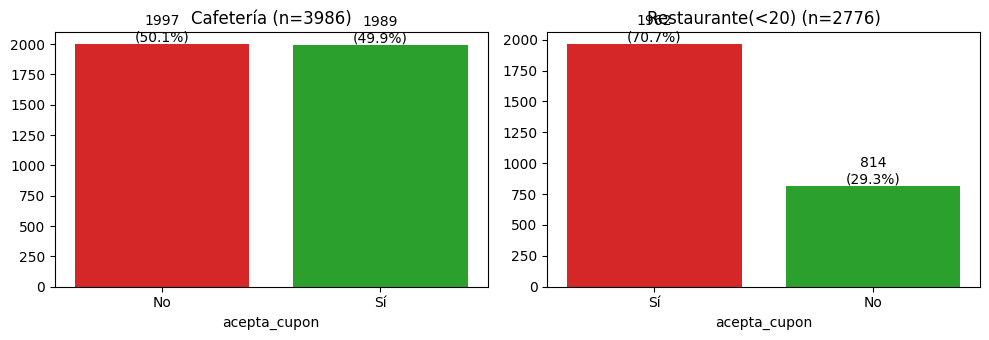

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (nombre, df) in zip(axes, [('Cafetería', cafeteria_raw), ('Restaurante(<20)', restaurante_raw)]):
    conteo = df['acepta_cupon'].value_counts()
    porcentaje = df['acepta_cupon'].value_counts(normalize=True) * 100
    ax.bar(conteo.index, conteo.values, color=['#d62728', '#2ca02c'])
    for i, (idx, val) in enumerate(conteo.items()):
        ax.text(i, val, f"{val}\n({porcentaje[idx]:.1f}%)", ha='center', va='bottom')
    ax.set_title(f'{nombre} (n={len(df)})')
    ax.set_xlabel('acepta_cupon')
plt.tight_layout()
plt.show()

### Calidad de los datos

Revisamos las cuatro dimensiones de calidad —completitud, unicidad, consistencia y validez— sobre el conjunto completo cuando aplica (algunos problemas, como `vehiculo`, afectan a los cinco tipos de cupón) y sobre cada subconjunto cuando corresponde.

#### Completitud

In [5]:
print("Valores nulos - Cafetería:")
print(cafeteria_raw.isna().sum()[cafeteria_raw.isna().sum() > 0])
print()
print("Valores nulos - Restaurante(<20):")
print(restaurante_raw.isna().sum()[restaurante_raw.isna().sum() > 0])

Valores nulos - Cafetería:
vehiculo                           3949
frecuencia_bar                       37
frecuencia_cafeteria                 72
frecuencia_comida_para_llevar        57
frecuencia_restaurante_menos_20      50
frecuencia_restaurante_20_a_50       55
dtype: int64

Valores nulos - Restaurante(<20):
vehiculo                           2751
frecuencia_bar                       23
frecuencia_cafeteria                 47
frecuencia_comida_para_llevar        34
frecuencia_restaurante_menos_20      27
frecuencia_restaurante_20_a_50       43
dtype: int64


**Cómo se lee.** Ambos subconjuntos tienen el mismo patrón de ausencias: `vehiculo` (que se revisa más abajo) y las cinco variables de frecuencia de consumo, cada una con menos del 2% de nulos. Al ser un porcentaje bajo y tratarse de variables categóricas ordinales, la estrategia adecuada (según la tabla de orientación de la práctica de limpieza) es imputar con la moda, dentro del pipeline, en la Sección 4.

#### Unicidad

In [6]:
print(f"Filas duplicadas en Cafetería:        {cafeteria_raw.duplicated().sum()}")
print(f"Filas duplicadas en Restaurante(<20):   {restaurante_raw.duplicated().sum()}")

Filas duplicadas en Cafetería:        7
Filas duplicadas en Restaurante(<20):   7


**Cómo se lee.** Ninguno de los dos subconjuntos tiene un identificador de conductor o de escenario, así que la única verificación posible es la de filas completamente idénticas (no hay forma de detectar "duplicados lógicos" sin un ID). Ambos subconjuntos tienen algunas: se eliminan en la Sección 3, antes de particionar en entrenamiento y prueba.

#### Consistencia

Revisamos si alguna columna categórica tiene variantes de formato (mayúsculas, espacios) que deberían representar la misma categoría.

In [7]:
columnas_categoricas = cafeteria_raw.select_dtypes(include='object').columns

inconsistencias = {}
for col in columnas_categoricas:
    valores = cafeteria_raw[col].dropna().unique()
    normalizados = {str(v).strip().upper() for v in valores}
    if len(normalizados) != len(valores):
        inconsistencias[col] = sorted(valores, key=str)

if inconsistencias:
    print("Columnas con posibles variantes de formato:")
    for col, valores in inconsistencias.items():
        print(f"  {col}: {valores}")
else:
    print("No se encontraron variantes de mayúsculas/espacios en ninguna columna categórica.")

No se encontraron variantes de mayúsculas/espacios en ninguna columna categórica.


**Cómo se lee.** A diferencia del caso de `FrenteMar` visto en la práctica de calidad de datos, aquí no aparece ninguna variante de formato: cada categoría tiene una única forma de escritura en todo el conjunto. No se requiere ninguna corrección de consistencia.

#### Validez

Comparamos los valores observados de cada variable con el dominio documentado en el diccionario de datos (Sección "Conjunto de datos" del enunciado), y verificamos que `temperatura` solo tome los tres valores fijos que describe el diccionario (30, 55 y 80 °F).

In [8]:
DOMINIOS_ESPERADOS = {
    'destino': {'Casa', 'Sin lugar urgente', 'Trabajo'},
    'acompanante': {'Solo', 'Amigo(s)', 'Hijo(s)', 'Pareja'},
    'clima': {'Soleado', 'Lluvioso', 'Nevado'},
    'vigencia_cupon': {'2 horas', '1 día'},
    'genero': {'Femenino', 'Masculino'},
    'estado_civil': {'Soltero(a)', 'Casado(a)', 'Unión libre', 'Divorciado(a)', 'Viudo(a)'},
    'tiene_hijos': {'Sí', 'No'},
    'misma_direccion': {'Sí', 'No'},
    'direccion_opuesta': {'Sí', 'No'},
    'tiempo_cupon_mayor_15min': {'Sí', 'No'},
    'tiempo_cupon_mayor_25min': {'Sí', 'No'},
}

problemas_validez = False
for col, dominio in DOMINIOS_ESPERADOS.items():
    valores_reales = set(cafeteria_raw[col].dropna().unique()) | set(restaurante_raw[col].dropna().unique())
    fuera_de_dominio = valores_reales - dominio
    if fuera_de_dominio:
        problemas_validez = True
        print(f"{col}: valores fuera del dominio esperado -> {fuera_de_dominio}")

if not problemas_validez:
    print("Todas las columnas categóricas revisadas están dentro del dominio documentado.")

print()
print("Valores únicos de temperatura:", sorted(data_raw['temperatura'].unique()), "(esperado: {30, 55, 80})")

Todas las columnas categóricas revisadas están dentro del dominio documentado.

Valores únicos de temperatura: [np.int64(30), np.int64(55), np.int64(80)] (esperado: {30, 55, 80})


**Cómo se lee.** No se encontraron valores fuera del dominio documentado en ninguna de las columnas categóricas revisadas, y `temperatura` solo toma los tres valores que describe el diccionario. A diferencia del caso de `Vista` en la práctica de calidad de datos (que sí tenía valores negativos y repdígitos), este conjunto de datos no presenta problemas de validez.

#### Variables redundantes o poco informativas

Más allá de las cuatro dimensiones, vale la pena revisar tres variables que, por su propia definición, son sospechosas de no aportar nada al modelo.

In [9]:
print("`vehiculo`: porcentaje de valores nulos")
print((data_raw['vehiculo'].isna().mean() * 100).round(1), "%")
print()
print("`tiempo_cupon_mayor_5min`: valores únicos presentes")
print(data_raw['tiempo_cupon_mayor_5min'].value_counts(dropna=False))
print()
print("`misma_direccion` vs. `direccion_opuesta` (tabla de contingencia):")
print(pd.crosstab(data_raw['misma_direccion'], data_raw['direccion_opuesta']))
print()
print("`tiempo_cupon_mayor_15min` vs. `tiempo_cupon_mayor_25min` (tabla de contingencia):")
print(pd.crosstab(data_raw['tiempo_cupon_mayor_15min'], data_raw['tiempo_cupon_mayor_25min']))

`vehiculo`: porcentaje de valores nulos
99.1 %

`tiempo_cupon_mayor_5min`: valores únicos presentes
tiempo_cupon_mayor_5min
Sí    12664
Name: count, dtype: int64

`misma_direccion` vs. `direccion_opuesta` (tabla de contingencia):
direccion_opuesta    No    Sí
misma_direccion              
No                    0  9944
Sí                 2720     0

`tiempo_cupon_mayor_15min` vs. `tiempo_cupon_mayor_25min` (tabla de contingencia):
tiempo_cupon_mayor_25min    No    Sí
tiempo_cupon_mayor_15min            
No                        5551     0
Sí                        5602  1511


**Cómo se lee.** `vehiculo` tiene nulos en más del 99% de las filas -casi nadie reportó esta variable, así que no puede aportar nada útil y no vale la pena ni imputarla-. `tiempo_cupon_mayor_5min` tiene un único valor posible (`Sí`) en **todo** el conjunto (no solo en estos dos subconjuntos): su varianza es cero, por lo que no distingue nada y cualquier modelo la ignoraría de todas formas. Y `misma_direccion` y `direccion_opuesta` son perfectamente complementarias (`misma_direccion = Sí` ocurre exactamente cuando `direccion_opuesta = No`, y viceversa): son la misma información contada dos veces, así que basta con conservar una. Estas tres observaciones se traducen directamente en decisiones de limpieza en la siguiente sección.

Hay un cuarto caso, más sutil, que **no** se elimina pero vale la pena anotar: `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` están perfectamente anidadas (nunca hay un caso de más de 25 minutos que no sea también de más de 15; la celda "No"/"Sí" de la tabla de contingencia queda en cero). Juntas equivalen a una sola variable ordinal de tres niveles (≤15 min, entre 15 y 25 min, >25 min) repartida en dos columnas binarias. No son exactamente redundantes como el par anterior -cada una aporta información que la otra no tiene por separado-, pero sí podrían resumirse en una sola variable ordinal sin perder información, lo que se retoma en la sección de Análisis de resultados.

## 3. Limpieza y preparación de los datos

Con base en lo anterior, las decisiones de limpieza son:

1. **Eliminar `vehiculo`**, por tener más del 99% de valores nulos (dimensión: completitud, caso extremo).
2. **Eliminar `tiempo_cupon_mayor_5min`**, por ser constante (varianza cero, no aporta información).
3. **Eliminar `direccion_opuesta`**, por ser redundante con `misma_direccion` (se conserva esta última porque es la forma más directa de leer "el cupón queda camino a donde ya se dirige el conductor").
4. **Eliminar filas duplicadas** (dimensión: unicidad), antes de separar entrenamiento y prueba, para que ninguna copia de una misma observación quede a ambos lados de la partición.
5. **Imputar las demás ausencias** (dimensión: completitud; las cinco variables de frecuencia, con menos del 2% de nulos cada una) con la **moda** de cada columna, dentro del pipeline, ya que son variables categóricas ordinales y no existe un "valor promedio" razonable para una categoría como "1 a 3 veces al mes".
6. **Codificar las variables según su naturaleza**: las que tienen un orden explícito en el diccionario de datos (`hora`, `edad`, `educacion`, `ingreso` y las cinco frecuencias) se codifican con `OrdinalEncoder` respetando ese orden; las nominales (sin orden), con `OneHotEncoder`. Esto se hace dentro del pipeline de modelado (Sección 4), no aquí, para evitar fuga de información entre entrenamiento y prueba.

No hubo que corregir nada de consistencia ni de validez, porque la revisión de la sección anterior no encontró problemas en esas dos dimensiones.

In [10]:
COLUMNAS_IRRELEVANTES = ['vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']

def limpiar(df):
    df = df.drop(columns=COLUMNAS_IRRELEVANTES)
    n_antes = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"  Filas: {n_antes} -> {len(df)} (se eliminaron {n_antes - len(df)} duplicadas)")
    return df

print("Cafetería:")
cafeteria = limpiar(cafeteria_raw)
print("Restaurante(<20):")
restaurante = limpiar(restaurante_raw)

Cafetería:
  Filas: 3986 -> 3979 (se eliminaron 7 duplicadas)
Restaurante(<20):
  Filas: 2776 -> 2769 (se eliminaron 7 duplicadas)


### Separación en entrenamiento y prueba

In [11]:
def separar(df, nombre):
    X = df.drop(columns='acepta_cupon')
    y = df['acepta_cupon']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
    )
    print(f"{nombre}: entrenamiento={len(X_train)} ({y_train.value_counts(normalize=True).round(3).to_dict()}), "
          f"prueba={len(X_test)} ({y_test.value_counts(normalize=True).round(3).to_dict()})")
    return X_train, X_test, y_train, y_test

X_train_caf, X_test_caf, y_train_caf, y_test_caf = separar(cafeteria, 'Cafetería')
X_train_res, X_test_res, y_train_res, y_test_res = separar(restaurante, 'Restaurante(<20)')

Cafetería: entrenamiento=2984 ({'No': 0.502, 'Sí': 0.498}), prueba=995 ({'No': 0.502, 'Sí': 0.498})


Restaurante(<20): entrenamiento=2076 ({'Sí': 0.708, 'No': 0.292}), prueba=693 ({'Sí': 0.707, 'No': 0.293})

## 4. Modelado

### 4.1. Preprocesamiento común

Las variables se agrupan en tres bloques, que se procesan de forma distinta dentro de un `ColumnTransformer`:

- **Ordinales** (`hora`, `edad`, `educacion`, `ingreso` y las cinco frecuencias de consumo): tienen un orden natural explícito en el diccionario de datos, así que se codifican con `OrdinalEncoder` indicando ese orden. Esto evita inventar relaciones de cercanía falsas que sí crearía un `OneHotEncoder` (para el que "nunca" y "más de 8" quedarían igual de "distintos" que "nunca" y "1 a 3").
- **Nominales** (destino, acompañante, clima, género, estado civil, ocupación, etc., y las variables binarias Sí/No): no tienen un orden natural, así que se codifican con `OneHotEncoder(handle_unknown='ignore', drop='if_binary')`. `handle_unknown='ignore'` evita que el pipeline falle si alguna categoría poco frecuente de `ocupacion` (hay 25 posibles) no aparece en algún pliegue de validación cruzada o en los datos de prueba; `drop='if_binary'` evita una columna redundante en las variables que solo tienen dos categorías.
- **Numérica** (`temperatura`): no tiene valores nulos, así que se deja pasar sin transformar (`'passthrough'`) en los modelos que no necesitan escalado.

Este mismo preprocesador se reutiliza para los tres algoritmos. Para la regresión logística se agrega, además, un `StandardScaler` sobre el resultado completo, porque esta técnica sí es sensible a la escala de las variables; los árboles y Random Forest no lo necesitan, porque dividen el espacio variable por variable sin comparar magnitudes entre ellas (tal como se vio en la práctica de árboles de decisión).

Siguiendo la convención usada en las prácticas de modelado, los pasos del pipeline se llaman `preprocessor` y `model`, de modo que los hiperparámetros de cada algoritmo se referencian en la búsqueda como `model__<hiperparámetro>`.

In [12]:
ORDEN_ORDINALES = {
    'hora': ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.'],
    'edad': ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más'],
    'educacion': ['Bachillerato incompleto', 'Bachillerato completo', 'Estudios universitarios sin título',
                  'Técnico/Tecnólogo', 'Pregrado', 'Posgrado (Maestría o Doctorado)'],
    'ingreso': ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999',
                '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999',
                '$100.000 o más'],
    'frecuencia_bar': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_cafeteria': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_comida_para_llevar': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_restaurante_menos_20': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_restaurante_20_a_50': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
}
COLUMNAS_ORDINALES = list(ORDEN_ORDINALES.keys())
CATEGORIAS_ORDINALES = [ORDEN_ORDINALES[c] for c in COLUMNAS_ORDINALES]

COLUMNAS_NOMINALES = ['destino', 'acompanante', 'clima', 'vigencia_cupon', 'genero', 'estado_civil',
                      'tiene_hijos', 'ocupacion', 'misma_direccion',
                      'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min']
COLUMNAS_NUMERICAS = ['temperatura']

# Validacion cruzada estratificada y mezclada, consistente con las practicas de modelado
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def construir_preprocesador(escalar):
    pipe_ordinal = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=CATEGORIAS_ORDINALES,
                                    handle_unknown='use_encoded_value', unknown_value=-1)),
    ])
    pipe_nominal = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Sin información')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False)),
    ])

    column_transformer = ColumnTransformer([
        ('ordinal', pipe_ordinal, COLUMNAS_ORDINALES),
        ('nominal', pipe_nominal, COLUMNAS_NOMINALES),
        ('numerica', 'passthrough', COLUMNAS_NUMERICAS),
    ])

    if escalar:
        return Pipeline([('columnas', column_transformer), ('scaler', StandardScaler())])
    return column_transformer


def ajustar_modelo(X_train, y_train, modelo, param_grid, escalar):
    preprocessor = construir_preprocesador(escalar=escalar)
    pipe = Pipeline([('preprocessor', preprocessor), ('model', modelo)])
    grid = GridSearchCV(pipe, param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    return grid


def evaluar_modelo(grid, X_test, y_test, nombre):
    y_pred = grid.predict(X_test)
    reporte = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    print(f"--- {nombre} ---")
    print("Mejores hiperparámetros:", grid.best_params_)
    print(f"F1-macro en validación cruzada: {grid.best_score_:.3f}")
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No', 'Sí'], cmap='Blues')
    plt.title(f'Matriz de confusión - {nombre}')
    plt.show()
    return reporte, y_pred

### 4.2. Regresión logística

Se explora el tipo de regularización (`l1` con el solver `liblinear`, `l2` con `liblinear` y con `lbfgs`) y la fuerza de la penalización `C`, siguiendo el mismo esquema de grilla con combinaciones válidas por solver que se usó en la práctica de regresión logística.

C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


--- Regresión logística - Cafetería ---
Mejores hiperparámetros: {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
F1-macro en validación cruzada: 0.706
              precision    recall  f1-score   support

          No       0.70      0.68      0.69       499
          Sí       0.69      0.70      0.69       496

    accuracy                           0.69       995
   macro avg       0.69      0.69      0.69       995
weighted avg       0.69      0.69      0.69       995



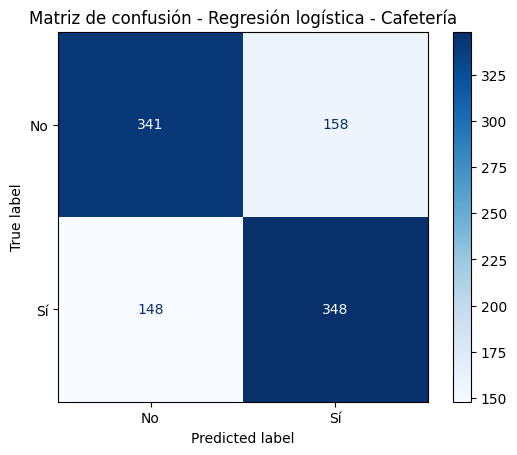

In [13]:
param_grid_logreg = [
    {'model__solver': ['liblinear'], 'model__penalty': ['l1', 'l2'], 'model__C': [0.01, 0.1, 1, 10]},
    {'model__solver': ['lbfgs'], 'model__penalty': ['l2'], 'model__C': [0.01, 0.1, 1, 10]},
]

grid_logreg_caf = ajustar_modelo(X_train_caf, y_train_caf,
                                  LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                                  param_grid_logreg, escalar=True)
grid_logreg_res = ajustar_modelo(X_train_res, y_train_res,
                                  LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                                  param_grid_logreg, escalar=True)

reporte_logreg_caf, pred_logreg_caf = evaluar_modelo(grid_logreg_caf, X_test_caf, y_test_caf, 'Regresión logística - Cafetería')

--- Regresión logística - Restaurante(<20) ---
Mejores hiperparámetros: {'model__C': 10, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
F1-macro en validación cruzada: 0.655
              precision    recall  f1-score   support

          No       0.60      0.41      0.49       203
          Sí       0.78      0.89      0.83       490

    accuracy                           0.75       693
   macro avg       0.69      0.65      0.66       693
weighted avg       0.73      0.75      0.73       693



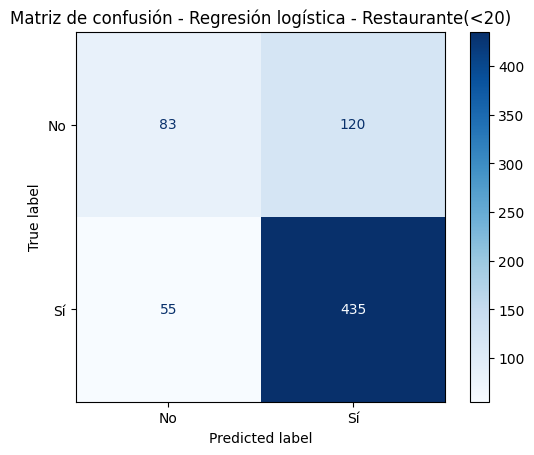

In [14]:
reporte_logreg_res, pred_logreg_res = evaluar_modelo(grid_logreg_res, X_test_res, y_test_res, 'Regresión logística - Restaurante(<20)')

**Cómo se lee.** En Cafetería, la regresión logística (`C=0.1`, penalización `l1`, solver `liblinear`) obtiene un F1-macro de 0.706 en validación cruzada y, sobre el conjunto de prueba, una exactitud de 0.69 con precisión y recall parecidos entre las dos clases (recall "No"=0.68, recall "Sí"=0.70). Como el problema está casi perfectamente balanceado (50.2% / 49.8%), el modelo no muestra ningún sesgo hacia una clase en particular.

En Restaurante(<20), el mejor modelo usa casi nada de regularización (`C=10`, `l2`, `lbfgs`), con un F1-macro de apenas 0.655 en validación cruzada. El comportamiento en prueba muestra con claridad el efecto del desbalance: el modelo predice bien la clase "Sí" (recall=0.89, precisión=0.78) pero le cuesta mucho identificar a quien **no** va a aceptar (recall "No"=0.41): de cada 10 personas que realmente rechazarían el cupón, el modelo apenas detecta a 4. Tiene sentido: con 70.8% de "Sí" en el entrenamiento, un modelo que casi siempre predice "Sí" ya obtiene una exactitud razonable, así que tiene poco incentivo para aprender a distinguir la clase minoritaria.

### 4.3. Árboles de decisión

Se explora la profundidad máxima, el número mínimo de observaciones por hoja y el criterio de división.

--- Árbol de decisión - Cafetería ---
Mejores hiperparámetros: {'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 1}
F1-macro en validación cruzada: 0.697
              precision    recall  f1-score   support

          No       0.70      0.66      0.68       499
          Sí       0.68      0.72      0.70       496

    accuracy                           0.69       995
   macro avg       0.69      0.69      0.69       995
weighted avg       0.69      0.69      0.69       995



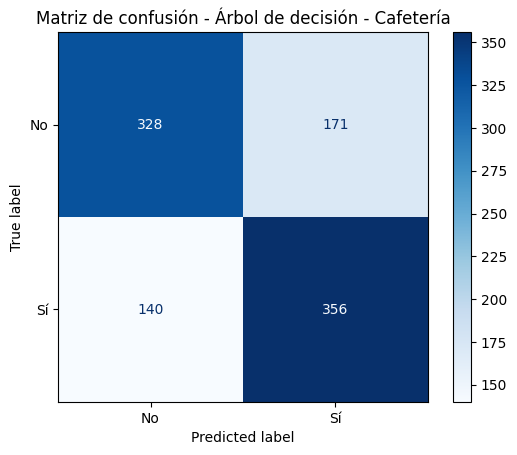

In [15]:
param_grid_tree = {
    'model__max_depth': [3, 5, 8, 12, None],
    'model__min_samples_leaf': [1, 5, 10, 20],
    'model__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_tree_caf = ajustar_modelo(X_train_caf, y_train_caf,
                                DecisionTreeClassifier(random_state=RANDOM_STATE),
                                param_grid_tree, escalar=False)
grid_tree_res = ajustar_modelo(X_train_res, y_train_res,
                                DecisionTreeClassifier(random_state=RANDOM_STATE),
                                param_grid_tree, escalar=False)

reporte_tree_caf, pred_tree_caf = evaluar_modelo(grid_tree_caf, X_test_caf, y_test_caf, 'Árbol de decisión - Cafetería')

--- Árbol de decisión - Restaurante(<20) ---
Mejores hiperparámetros: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 20}
F1-macro en validación cruzada: 0.648
              precision    recall  f1-score   support

          No       0.69      0.41      0.52       203
          Sí       0.79      0.92      0.85       490

    accuracy                           0.77       693
   macro avg       0.74      0.67      0.68       693
weighted avg       0.76      0.77      0.75       693



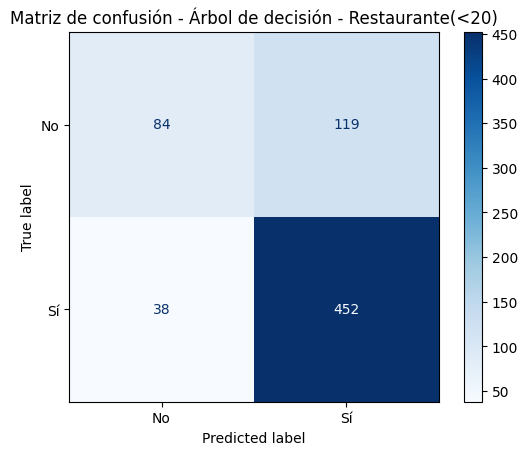

In [16]:
reporte_tree_res, pred_tree_res = evaluar_modelo(grid_tree_res, X_test_res, y_test_res, 'Árbol de decisión - Restaurante(<20)')

**Cómo se lee.** El árbol de Cafetería (`entropy`, profundidad 8, `min_samples_leaf=1`) obtiene un desempeño muy similar al de la regresión logística (F1-macro CV=0.697, F1-macro test=0.687): no hay una ventaja clara de uno sobre el otro en este cupón, aunque el árbol necesita bastante más profundidad para igualar al modelo lineal, señal de que aquí la relación entre variables no es tan simple como una combinación lineal.

Para Restaurante(<20), la búsqueda eligió `entropy`, profundidad 5 y hojas de al menos 20 observaciones -relativamente poco profundo y con hojas grandes-, lo cual sugiere que, con árboles más finos, el modelo empieza a sobreajustar el patrón mayoritario sin ganar generalización. El resultado en prueba (recall "No"=0.41, parecido al de la regresión logística) muestra el mismo problema frente al desbalance: tampoco logra identificar bien a quienes rechazan el cupón.

### 4.4. Random Forest

## Uso de herramientas de IA generativa